In [ ]:
import numpy as np, pandas as pd
from pandas_datareader import data as web

PREDICTORS = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy'] #baseline metrics
START = '1978'                       # UMCSENT becomes monthly 1978-01

raw = web.DataReader(['UMCSENT','PAYEMS','UNRATE','CPIAUCSL','AHETPI','GDPC1'],
                     'fred', '1947-01-01')

idx = pd.date_range(raw.index.min(), raw.index.max(), freq='MS') #keep all dates even if they are NAN
yoy = lambda s, p: s.dropna().pct_change(p) * 100

# quarterly -> monthly: each quarter's value covers its own 3 months, then stops
gdp_q = yoy(raw.GDPC1, 4)
gdp_m = gdp_q.reindex(idx.union(gdp_q.index)).ffill(limit=2).reindex(idx)

d = pd.DataFrame({
    'sentiment':      raw.UMCSENT.dropna(),      # NSA; monthly from 1978-01
    'unemployment':   raw.UNRATE.dropna(),       # already a rate, keep level
    'jobs_yoy':       yoy(raw.PAYEMS, 12),
    'inflation_yoy':  yoy(raw.CPIAUCSL, 12),
    'wages_yoy':      yoy(raw.AHETPI, 12),       # kept for comparison only
    'real_wages_yoy': yoy(raw.AHETPI / raw.CPIAUCSL, 12),
    'gdp_yoy':        gdp_m,
}).reindex(idx)
d.index.name = 'date'

# quarterly aggregation -- no GDP imputation, matches Gordon's frequency
dq = d.loc[START:].resample('QS').mean()

print(d.loc[START:, ['sentiment'] + PREDICTORS].dropna().shape)   # ~(581, 6)
print(dq[['sentiment'] + PREDICTORS].dropna().shape)              # ~(194, 6)

(581, 6)
(194, 6)


/var/folders/xg/2jx4h1913bx28fptfgb7xjx00000gn/T/ipykernel_17038/366840621.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  raw = web.DataReader(['UMCSENT','PAYEMS','UNRATE','CPIAUCSL','AHETPI','GDPC1'],


In [2]:
d["sentiment"].dropna().describe()

count    676.000000
mean      84.367751
std       13.752138
min       44.800000
25%       73.975000
50%       88.300000
75%       94.625000
max      112.000000
Name: sentiment, dtype: float64

In [ ]:
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

SPLIT = '2022'


d = d.loc['1978':, ['sentiment'] + PREDICTORS].dropna()

y = d['sentiment'].values
is_train = d.index < SPLIT
is_test = ~is_train

# standardize with TRAINING mean and sd only
X = d[PREDICTORS]
Z = ((X - X[is_train].mean()) / X[is_train].std()).values

with pm.Model(coords={'predictor': PREDICTORS}) as baseline:
    alpha = pm.Normal('alpha', mu=85, sigma=20)
    beta = pm.Normal('beta', mu=0, sigma=5, dims='predictor')
    sigma = pm.HalfNormal('sigma', sigma=10)
    pm.Normal('y', mu=alpha + pm.math.dot(Z[is_train], beta),
              sigma=sigma, observed=y[is_train])
    idata = pm.sample(1000, tune=1000, chains=4, random_seed=1)

print(az.summary(idata, var_names=['alpha', 'beta', 'sigma'], hdi_prob=0.89))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


                        mean     sd  hdi_5.5%  hdi_94.5%  mcse_mean  mcse_sd  \
alpha                 86.004  0.341    85.464     86.548      0.005    0.006   
beta[unemployment]    -5.384  0.388    -6.020     -4.787      0.006    0.006   
beta[jobs_yoy]        -0.816  0.704    -1.909      0.321      0.014    0.010   
beta[inflation_yoy]   -4.040  0.543    -4.893     -3.163      0.010    0.008   
beta[real_wages_yoy]   1.193  0.596     0.262      2.167      0.011    0.009   
beta[gdp_yoy]          5.496  0.606     4.557      6.470      0.011    0.009   
sigma                  7.766  0.236     7.384      8.133      0.003    0.004   

                      ess_bulk  ess_tail  r_hat  
alpha                   4638.0    2733.0    1.0  
beta[unemployment]      4341.0    3003.0    1.0  
beta[jobs_yoy]          2664.0    2897.0    1.0  
beta[inflation_yoy]     3068.0    2807.0    1.0  
beta[real_wages_yoy]    2830.0    2910.0    1.0  
beta[gdp_yoy]           2904.0    2836.0    1.0  
sigma    

In [ ]:
alpha_draws = idata.posterior['alpha'].values.reshape(-1)
beta_draws = idata.posterior['beta'].values.reshape(-1, len(PREDICTORS))
sigma_draws = idata.posterior['sigma'].values.reshape(-1)

mu_draws = alpha_draws[:, None] + beta_draws @ Z.T           # systematic part
rng = np.random.default_rng(1)
pred_draws = mu_draws + rng.normal(0, sigma_draws[:, None], mu_draws.shape)  # + noise

mu = mu_draws.mean(axis=0)
mu_lo, mu_hi = np.percentile(mu_draws, [5.5, 94.5], axis=0)       # 89% on the mean
pi_lo, pi_hi = np.percentile(pred_draws, [5.5, 94.5], axis=0)     # 89% predictive

inside = (y >= pi_lo) & (y <= pi_hi)
gap_draws = (y[is_test] - mu_draws[:, is_test]).mean(axis=1)
resid = y - mu

print(f'\nR2 train            {1 - np.var(resid[is_train]) / np.var(y[is_train]):.3f}')
print(f'RMSE train          {np.sqrt(np.mean(resid[is_train] ** 2)):.2f}')
print(f'RMSE test           {np.sqrt(np.mean(resid[is_test] ** 2)):.2f}')
print(f'coverage, train     {100 * inside[is_train].mean():.1f}%  (should be near 89%)')
print(f'coverage, 2022+     {100 * inside[is_test].mean():.1f}%  '
      f'({inside[is_test].sum()} of {is_test.sum()} months)')
print(f'GAP 2022+           {gap_draws.mean():+.2f}  '
      f'[89% {np.percentile(gap_draws, 5.5):+.2f}, {np.percentile(gap_draws, 94.5):+.2f}]')
by_year = pd.Series(resid[is_test], index=d.index[is_test]).groupby(lambda t: t.year).mean()
print('by year: ' + '  '.join(f'{yr} {v:+.1f}' for yr, v in by_year.items()))

pd.DataFrame({'date': d.index, 'actual': y, 'predicted': mu,
              'pred_lo': pi_lo, 'pred_hi': pi_hi, 'train': is_train}
             ).to_csv('baseline_fits.csv', index=False)


R2 train            0.623
RMSE train          7.71
RMSE test           30.15
coverage, train     90.0%  (should be near 89%)
coverage, 2022+     0.0%  (0 of 53 months)
GAP 2022+           -29.21  [89% -30.23, -28.21]
by year: 2022 -25.5  2023 -28.4  2024 -22.4  2025 -35.5  2026 -40.2



wrote baseline_fits.csv, baseline_plot.png


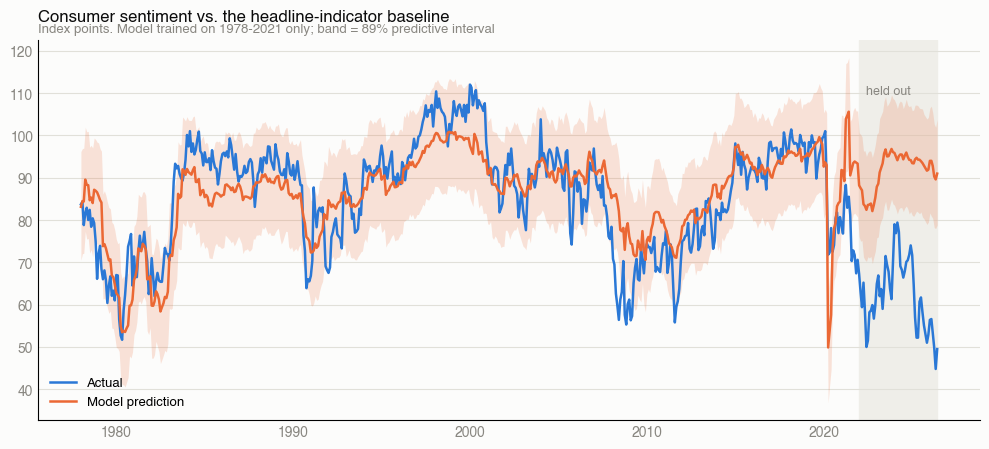

In [8]:
SURF, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9'
BLUE, ORANGE = '#2a78d6', '#eb6834'

fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=SURF)
ax.set_facecolor(SURF)
ax.grid(axis='y', color=GRID, lw=0.8)
ax.set_axisbelow(True)

# shade the held-out period so nobody mistakes it for fitted data
ax.axvspan(pd.Timestamp(SPLIT), d.index.max(), color='#efeee9', zorder=0)
ax.text(pd.Timestamp(SPLIT), 112, '  held out', color=MUTED, fontsize=9, va='top')

ax.fill_between(d.index, pi_lo, pi_hi, color=ORANGE, alpha=0.18, lw=0, zorder=2)
ax.plot(d.index, y, color=BLUE, lw=1.8, zorder=3, label='Actual')
ax.plot(d.index, mu, color=ORANGE, lw=1.8, zorder=4, label='Model prediction')

for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, loc='lower left', fontsize=9.5)
ax.set_title('Consumer sentiment vs. the headline-indicator baseline',
             color=INK, fontsize=12, loc='left', pad=14)
ax.text(0, 1.015, 'Index points. Model trained on 1978-2021 only; '
        'band = 89% predictive interval',
        transform=ax.transAxes, color=MUTED, fontsize=9.5, va='bottom')
fig.tight_layout()
fig.savefig('baseline_plot.png', dpi=200, facecolor=SURF)
print('\nwrote baseline_fits.csv, baseline_plot.png')

In [9]:
import numpy as np, pandas as pd
from pandas_datareader import data as web

PREDICTORS = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy']   # baseline metrics
HOUSEHOLD = ['mortgage_rates_monthly', 'food_prices_yoy', 'rent_prices_yoy',
             'gas_prices_yoy', 'house_prices_yoy', 'rdpi_yoy',
             'savings', 'credit_yoy', 'revolving_ratio']                                 # household metrics
START = '1978'

baseline_codes = ['UMCSENT', 'PAYEMS', 'UNRATE', 'CPIAUCSL', 'AHETPI', 'GDPC1']
household_codes = ['MORTGAGE30US', 'CUSR0000SAF11', 'CUUR0000SEHA', 'CUSR0000SETB01',
                   'USSTHPI', 'A229RX0', 'PSAVERT', 'REVOLSL', 'DSPI']

raw = web.DataReader(baseline_codes + household_codes, 'fred', '1947-01-01')

idx = pd.date_range(raw.index.min(), raw.index.max(), freq='MS')   # keep all dates even if NaN
yoy = lambda s, p: s.dropna().pct_change(p) * 100

# quarterly -> monthly: each quarter's value covers its own 3 months, then stops
gdp_q = yoy(raw.GDPC1, 4)
gdp_m = gdp_q.reindex(idx.union(gdp_q.index)).ffill(limit=2).reindex(idx)
hpi_q = yoy(raw.USSTHPI, 4)                       # house prices are quarterly too: 4, not 12
hpi_m = hpi_q.reindex(idx.union(hpi_q.index)).ffill(limit=2).reindex(idx)

d = pd.DataFrame({
    'sentiment':      raw.UMCSENT.dropna(),
    'unemployment':   raw.UNRATE.dropna(),
    'jobs_yoy':       yoy(raw.PAYEMS, 12),
    'inflation_yoy':  yoy(raw.CPIAUCSL, 12),
    'real_wages_yoy': yoy(raw.AHETPI / raw.CPIAUCSL, 12),
    'gdp_yoy':        gdp_m,
    'mortgage_rates_monthly': raw.MORTGAGE30US.dropna().resample('MS').mean(),   # weekly -> monthly average
    'food_prices_yoy':  yoy(raw.CUSR0000SAF11, 12),
    'rent_prices_yoy':  yoy(raw.CUUR0000SEHA, 12),
    'gas_prices_yoy':   yoy(raw.CUSR0000SETB01, 12),
    'house_prices_yoy': hpi_m,
    'rdpi_yoy':         yoy(raw.A229RX0, 12),
    'savings':          raw.PSAVERT.dropna(),
    'credit_yoy':       yoy(raw.REVOLSL, 12),
    'revolving_ratio':  ((raw.REVOLSL / 1000) / raw.DSPI * 100).dropna(),
}).reindex(idx)
d.index.name = 'date'

/var/folders/xg/2jx4h1913bx28fptfgb7xjx00000gn/T/ipykernel_17038/3003456250.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  raw = web.DataReader(baseline_codes + household_codes, 'fred', '1947-01-01')


In [10]:
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

SPLIT = '2022'

# ONE common sample so all three models use the same months
d = d.loc[START:, ['sentiment'] + PREDICTORS + HOUSEHOLD].dropna()
print(d.shape)        # ~(581, 15)

y = d['sentiment'].values
is_train = d.index < SPLIT
is_test = ~is_train

(581, 15)


In [11]:
def plot_model(mu, pi_lo, pi_hi, title):
    SURF, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9'
    BLUE, ORANGE = '#2a78d6', '#eb6834'

    fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=SURF)
    ax.set_facecolor(SURF)
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)

    ax.axvspan(pd.Timestamp(SPLIT), d.index.max(), color='#efeee9', zorder=0)
    ax.text(pd.Timestamp(SPLIT), 112, '  held out', color=MUTED, fontsize=9, va='top')

    ax.fill_between(d.index, pi_lo, pi_hi, color=ORANGE, alpha=0.18, lw=0, zorder=2)
    ax.plot(d.index, y, color=BLUE, lw=1.8, zorder=3, label='Actual')
    ax.plot(d.index, mu, color=ORANGE, lw=1.8, zorder=4, label='Model prediction')

    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, length=0)
    ax.legend(frameon=False, loc='lower left', fontsize=9.5)
    ax.set_title(title, color=INK, fontsize=12, loc='left', pad=14)
    ax.text(0, 1.015, 'Index points. Model trained on 1978-2021 only; band = 89% predictive interval',
            transform=ax.transAxes, color=MUTED, fontsize=9.5, va='bottom')
    fig.tight_layout()
    plt.show()

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


                                mean     sd  hdi_5.5%  hdi_94.5%  mcse_mean  \
alpha                         86.009  0.256    85.622     86.434      0.004   
beta[unemployment]            -7.107  0.471    -7.866     -6.396      0.009   
beta[jobs_yoy]                 1.301  0.733     0.090      2.433      0.015   
beta[inflation_yoy]          -11.627  1.098   -13.466     -9.936      0.025   
beta[real_wages_yoy]          -0.791  0.588    -1.753      0.121      0.010   
beta[gdp_yoy]                  2.319  0.642     1.311      3.332      0.013   
beta[mortgage_rates_monthly]   7.468  0.662     6.408      8.523      0.014   
beta[food_prices_yoy]         -1.035  0.427    -1.706     -0.353      0.008   
beta[rent_prices_yoy]          1.146  0.667     0.160      2.290      0.013   
beta[gas_prices_yoy]           1.360  0.566     0.426      2.246      0.011   
beta[house_prices_yoy]         2.047  0.401     1.399      2.673      0.007   
beta[rdpi_yoy]                 0.780  0.428     0.10

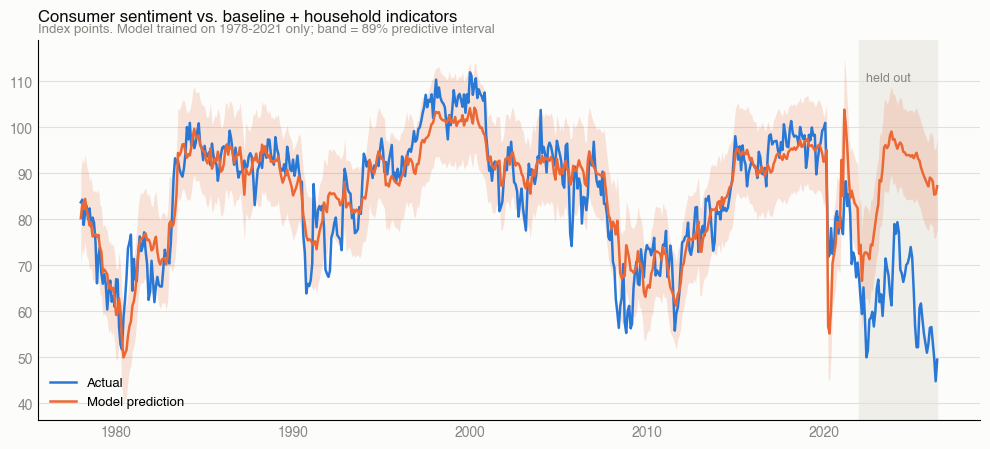

In [12]:
COLS = PREDICTORS + HOUSEHOLD

X = d[COLS]
Z = ((X - X[is_train].mean()) / X[is_train].std()).values    # TRAINING mean and sd only

with pm.Model(coords={'predictor': COLS}) as both_model:
    alpha = pm.Normal('alpha', mu=85, sigma=20)
    beta = pm.Normal('beta', mu=0, sigma=5, dims='predictor')
    sigma = pm.HalfNormal('sigma', sigma=10)
    pm.Normal('y', mu=alpha + pm.math.dot(Z[is_train], beta),
              sigma=sigma, observed=y[is_train])
    idata_both = pm.sample(1000, tune=1000, chains=4, random_seed=1)

print(az.summary(idata_both, var_names=['alpha', 'beta', 'sigma'], hdi_prob=0.89))

# predictions for every month, one path per posterior draw
alpha_draws = idata_both.posterior['alpha'].values.reshape(-1)
beta_draws = idata_both.posterior['beta'].values.reshape(-1, len(COLS))
sigma_draws = idata_both.posterior['sigma'].values.reshape(-1)
mu_draws = alpha_draws[:, None] + beta_draws @ Z.T
pred_draws = mu_draws + np.random.default_rng(1).normal(0, sigma_draws[:, None], mu_draws.shape)

mu = mu_draws.mean(axis=0)
pi_lo, pi_hi = np.percentile(pred_draws, [5.5, 94.5], axis=0)
inside = (y >= pi_lo) & (y <= pi_hi)
resid = y - mu
gap_draws = (y[is_test] - mu_draws[:, is_test]).mean(axis=1)

print(f'R2 train        {1 - np.var(resid[is_train]) / np.var(y[is_train]):.3f}')
print(f'RMSE test       {np.sqrt(np.mean(resid[is_test] ** 2)):.2f}')
print(f'coverage train  {100 * inside[is_train].mean():.1f}%')
print(f'coverage 2022+  {100 * inside[is_test].mean():.1f}%  ({inside[is_test].sum()} of {is_test.sum()})')
print(f'GAP 2022+       {gap_draws.mean():+.2f}  [89% {np.percentile(gap_draws, 5.5):+.2f}, {np.percentile(gap_draws, 94.5):+.2f}]')

plot_model(mu, pi_lo, pi_hi, 'Consumer sentiment vs. baseline + household indicators')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


                                mean     sd  hdi_5.5%  hdi_94.5%  mcse_mean  \
alpha                         86.007  0.350    85.465     86.555      0.005   
beta[mortgage_rates_monthly]   3.026  0.705     1.958      4.189      0.013   
beta[food_prices_yoy]         -3.973  0.430    -4.680     -3.293      0.007   
beta[rent_prices_yoy]         -2.935  0.639    -3.818     -1.759      0.012   
beta[gas_prices_yoy]          -2.184  0.394    -2.807     -1.566      0.006   
beta[house_prices_yoy]         4.501  0.453     3.810      5.240      0.008   
beta[rdpi_yoy]                 4.987  0.463     4.214      5.698      0.009   
beta[savings]                 -4.967  0.719    -6.083     -3.813      0.014   
beta[credit_yoy]               3.307  0.524     2.483      4.130      0.010   
beta[revolving_ratio]          1.245  0.781     0.074      2.575      0.014   
sigma                          8.075  0.252     7.670      8.462      0.004   

                              mcse_sd  ess_bulk  es

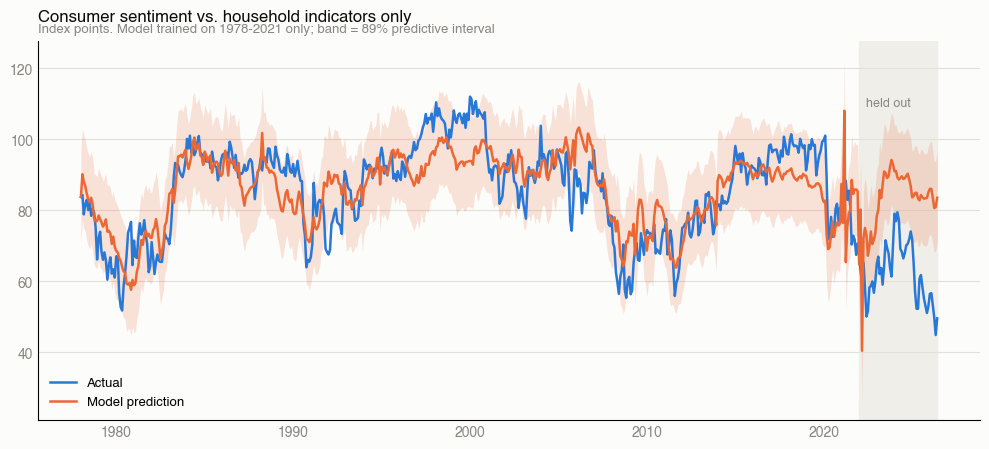

In [13]:
COLS = HOUSEHOLD

X = d[COLS]
Z = ((X - X[is_train].mean()) / X[is_train].std()).values    # TRAINING mean and sd only

with pm.Model(coords={'predictor': COLS}) as hh_model:
    alpha = pm.Normal('alpha', mu=85, sigma=20)
    beta = pm.Normal('beta', mu=0, sigma=5, dims='predictor')
    sigma = pm.HalfNormal('sigma', sigma=10)
    pm.Normal('y', mu=alpha + pm.math.dot(Z[is_train], beta),
              sigma=sigma, observed=y[is_train])
    idata_hh = pm.sample(1000, tune=1000, chains=4, random_seed=1)

print(az.summary(idata_hh, var_names=['alpha', 'beta', 'sigma'], hdi_prob=0.89))

alpha_draws = idata_hh.posterior['alpha'].values.reshape(-1)
beta_draws = idata_hh.posterior['beta'].values.reshape(-1, len(COLS))
sigma_draws = idata_hh.posterior['sigma'].values.reshape(-1)
mu_draws = alpha_draws[:, None] + beta_draws @ Z.T
pred_draws = mu_draws + np.random.default_rng(1).normal(0, sigma_draws[:, None], mu_draws.shape)

mu = mu_draws.mean(axis=0)
pi_lo, pi_hi = np.percentile(pred_draws, [5.5, 94.5], axis=0)
inside = (y >= pi_lo) & (y <= pi_hi)
resid = y - mu
gap_draws = (y[is_test] - mu_draws[:, is_test]).mean(axis=1)

print(f'R2 train        {1 - np.var(resid[is_train]) / np.var(y[is_train]):.3f}')
print(f'RMSE test       {np.sqrt(np.mean(resid[is_test] ** 2)):.2f}')
print(f'coverage train  {100 * inside[is_train].mean():.1f}%')
print(f'coverage 2022+  {100 * inside[is_test].mean():.1f}%  ({inside[is_test].sum()} of {is_test.sum()})')
print(f'GAP 2022+       {gap_draws.mean():+.2f}  [89% {np.percentile(gap_draws, 5.5):+.2f}, {np.percentile(gap_draws, 94.5):+.2f}]')

plot_model(mu, pi_lo, pi_hi, 'Consumer sentiment vs. household indicators only')

In [15]:
import numpy as np, pandas as pd
import numpy.linalg as la
import matplotlib.pyplot as plt

ANES_PATH = '/Users/dylannewman/Documents/GitHub/ucla-capstone-project/anes_timeseries_cdf_csv_20260205.csv'
SPLIT_YEAR = 2012

# party holding the White House during each ANES fieldwork
PRES = {1952:'D',1954:'R',1956:'R',1958:'R',1960:'R',1962:'D',1964:'D',1966:'D',1968:'D',
        1970:'R',1972:'R',1974:'R',1976:'R',1978:'D',1980:'D',1982:'R',1984:'R',1986:'R',
        1988:'R',1990:'R',1992:'R',1994:'D',1996:'D',1998:'D',2000:'D',2002:'R',2004:'R',
        2006:'R',2008:'R',2010:'D',2012:'D',2016:'D',2020:'R',2024:'D'}

raw = pd.read_csv(ANES_PATH, low_memory=False)
num = lambda s: pd.to_numeric(s, errors='coerce')

o = pd.DataFrame({
    'year': num(raw.VCF0004),
    'pid':  num(raw.VCF0303),          # 1 Democrat, 2 Independent, 3 Republican
    'natl': num(raw.VCF0870),          # national economy: 1 better, 3 same, 5 worse
    'own':  num(raw.VCF0880),          # own finances:     1 better, 2 same, 3 worse
    'w':    num(raw.VCF0009z),
})
o['w'] = o.w.fillna(1.0)
o.loc[o.w <= 0, 'w'] = 1.0
o['natl_net'] = o.natl.map({1: 100.0, 3: 0.0, 5: -100.0})
o['own_net'] = o.own.map({1: 100.0, 2: 0.0, 3: -100.0})
o = o[o.pid.isin([1, 2, 3])]

# in-party = shares the president's party; out-party = the other one
pres = o.year.map(PRES)
o['side'] = np.where(o.pid == 2, 'independent',
             np.where(((o.pid == 1) & (pres == 'D')) | ((o.pid == 3) & (pres == 'R')),
                      'in-party', 'out-party'))

In [16]:
fits = pd.read_csv('baseline_fits.csv', parse_dates=['date'])
pred = fits.groupby(fits.date.dt.year)['predicted'].mean()

In [17]:
def wmean(g, col):
    m = g[col].notna()
    return np.average(g.loc[m, col], weights=g.loc[m, 'w']) if m.sum() > 30 else np.nan

GROUPS = ['everyone', 'in-party', 'out-party', 'independent']
results = {}

for item, label in [('own_net', 'OWN FINANCES'), ('natl_net', 'NATIONAL ECONOMY')]:
    rows = []
    for yr, g in o.groupby('year'):
        row = {'year': int(yr), 'everyone': wmean(g, item)}
        for side in GROUPS[1:]:
            row[side] = wmean(g[g.side == side], item)
        rows.append(row)
    t = pd.DataFrame(rows).set_index('year').join(pred.rename('pred'), how='inner').dropna()

    # calibrate each group on pre-2012 years, then measure its miss afterward
    resid = pd.DataFrame(index=t.index)
    pre = t[t.index < SPLIT_YEAR]
    for grp in GROUPS:
        X = np.column_stack([np.ones(len(pre)), pre.pred])
        b = la.lstsq(X, pre[grp], rcond=None)[0]
        resid[grp] = t[grp] - (b[0] + b[1] * t.pred)

    print(f'--- {label}: shift after {SPLIT_YEAR}, net of economic conditions ---')
    for grp in GROUPS:
        print(f'  {grp:12s} {resid[grp][resid.index >= SPLIT_YEAR].mean():+6.1f}   '
              f'(2024: {resid[grp].get(2024, np.nan):+6.1f})')
    results[item] = resid

--- OWN FINANCES: shift after 2012, net of economic conditions ---
  everyone       -7.2   (2024:  -20.5)
  in-party       +1.8   (2024:  -10.6)
  out-party     -16.4   (2024:  -33.8)
  independent   -17.6   (2024:  -21.7)
--- NATIONAL ECONOMY: shift after 2012, net of economic conditions ---
  everyone       +3.4   (2024:  -35.1)
  in-party      +23.4   (2024:  -12.7)
  out-party     -19.2   (2024:  -60.3)
  independent    -3.6   (2024:  -51.5)


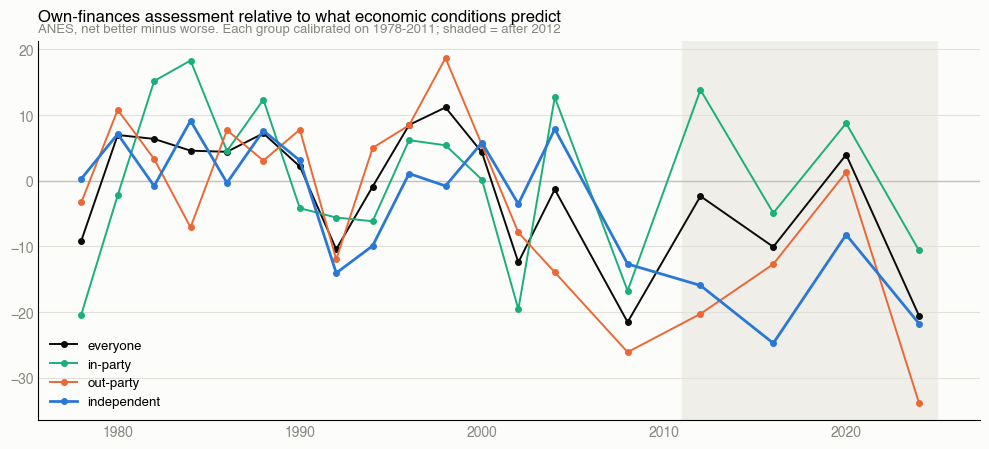

In [18]:
resid = results['own_net']
COLORS = {'everyone': '#0b0b0b', 'in-party': '#1baf7a',
          'out-party': '#eb6834', 'independent': '#2a78d6'}

fig, ax = plt.subplots(figsize=(10, 4.6), facecolor='#fcfcfb')
ax.set_facecolor('#fcfcfb')
ax.axhline(0, color='#c3c2b7', lw=1)
ax.axvspan(SPLIT_YEAR - 1, resid.index.max() + 1, color='#efeee9', zorder=0)
for grp in GROUPS:
    ax.plot(resid.index, resid[grp], marker='o', ms=4, lw=2 if grp == 'independent' else 1.4,
            color=COLORS[grp], label=grp)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.tick_params(colors='#898781', length=0)
ax.grid(axis='y', color='#e1e0d9', lw=0.8)
ax.legend(frameon=False, loc='lower left', fontsize=9.5)
ax.set_title('Own-finances assessment relative to what economic conditions predict',
             fontsize=12, loc='left', pad=14)
ax.text(0, 1.015, 'ANES, net better minus worse. Each group calibrated on 1978-2011; shaded = after 2012',
        transform=ax.transAxes, color='#898781', fontsize=9.5, va='bottom')
fig.tight_layout()
plt.show()